# Analyse du chômage par province et préfecture

## 1. Introduction et objectifs

Ce notebook est consacré à l'analyse du chômage au Maroc à l'échelle des provinces et préfectures.

L'objectif principal est d'explorer les disparités géographiques du chômage et d'identifier les territoires les plus touchés.

Cette analyse permettra notamment de :
- Étudier la répartition du chômage entre les provinces et préfectures.
- Identifier les territoires présentant les taux de chômage les plus élevés et les plus faibles.
- Comparer les disparités géographiques.
- Produire des visualisations pour faciliter l'interprétation des résultats.

Les données utilisées proviennent du Haut-Commissariat au Plan (HCP).

In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Project paths
current_dir = Path.cwd()

if (current_dir / "data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError("Project root not found.")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

# Create output folders if they do not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())
print("Processed data folder exists:", PROCESSED_DIR.exists())
print("Figures folder exists:", FIGURES_DIR.exists())

Project root: c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence
Raw data folder exists: True
Processed data folder exists: True
Figures folder exists: True


## 2. Chargement et exploration initiale des données

### 2.1. Identification des fichiers sources

Avant de charger le dataset, nous allons identifier les fichiers Excel disponibles dans le dossier `data/raw`.

In [3]:
print("Fichiers disponibles dans data/raw :\n")

for file in sorted(RAW_DIR.iterdir()):
    print(file.name)

Fichiers disponibles dans data/raw :

i_i3287_data.xlsx
i_i3287_metadata.xlsx
i_i4249_data.xlsx
i_i4249_metadata.xlsx
i_imt_txch_02_data.xlsx
i_imt_txch_02_metadata.xlsx
i_imt_txemp_02_data.xlsx


In [4]:
# Identify files related to unemployment by province/prefecture

unemployment_files = list(RAW_DIR.glob("*txch*"))

print("Fichiers liés au chômage par province/préfecture :\n")

for file in unemployment_files:
    print(file.name)

print("\nNombre de fichiers trouvés :", len(unemployment_files))

Fichiers liés au chômage par province/préfecture :

i_imt_txch_02_data.xlsx
i_imt_txch_02_metadata.xlsx

Nombre de fichiers trouvés : 2


### 2.2. Chargement du fichier de données

Nous allons charger le fichier Excel contenant les données du chômage par province et préfecture.

Avant d'examiner les observations, nous vérifions les feuilles disponibles dans le classeur.

In [5]:
# Define the dataset path
PROVINCE_FILE = RAW_DIR / "i_imt_txch_02_data.xlsx"

# Open the Excel workbook
excel_data = pd.ExcelFile(PROVINCE_FILE)

print("Feuilles disponibles :", excel_data.sheet_names)

Feuilles disponibles : ['Data']


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


### 2.3. Exploration du contenu brut

Nous affichons les premières lignes du fichier sans définir de ligne d'en-tête.

Cette étape permet d'identifier la structure du tableau et la ligne contenant les noms des colonnes.

In [7]:
# Read the first rows without assigning column names
df_province_preview = pd.read_excel(
    PROVINCE_FILE,
    sheet_name="Data",
    header=None
)

print("Dimensions du fichier brut :", df_province_preview.shape)

display(df_province_preview.head(12))

Dimensions du fichier brut : (181, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,Taux de chômage selon les Provinces/Préfecture...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
2,National,Al Hoceima,6.7,8,10.2,8.5,10,11.4,8.4,7,7.8
3,National,Chefchaouen,4.6,6,6,5,4.6,5.5,4.7,3.8,3.9
4,National,Larache,8.7,9.1,10.1,9.6,9.2,9.2,6.5,6.5,9.1
5,National,Ouezzane,7.4,6.4,4.9,4.3,5.5,4.5,8.4,7.2,7.2
6,National,Tanger-Assilah,10.9,12.1,10.5,12.4,12.9,11,8.9,7.4,8.4
7,National,Tétouan,11.2,12,12.8,11.1,11.7,13.2,11.7,11.1,11.4
8,National,M'Diq-Fnideq,15.3,18,18.4,14.9,19.7,18.8,13.1,11.3,10.1
9,National,Berkane,20.8,18.7,20.5,17.5,19.6,19.8,11.9,15.5,18.1


## 3. Chargement et compréhension des données

### 3.1. Chargement du dataset

La première ligne du fichier Excel contient le titre du tableau.
La deuxième ligne contient les noms des colonnes.

Nous utilisons donc `header=1` afin de charger correctement les données.

In [8]:
# Load the dataset using the correct header row

df_province_raw = pd.read_excel(
    PROVINCE_FILE,
    sheet_name="Data",
    header=1
)

print("Dimensions du dataset :", df_province_raw.shape)

print("\nNoms des colonnes :")
print(df_province_raw.columns.tolist())

print("\nAperçu des 10 premières lignes :")
display(df_province_raw.head(10))

Dimensions du dataset : (179, 11)

Noms des colonnes :
['Milieu', 'Provinces/Préfectures', '2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017']

Aperçu des 10 premières lignes :


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
0,National,Al Hoceima,6.7,8,10.2,8.5,10,11.4,8.4,7,7.8
1,National,Chefchaouen,4.6,6,6,5,4.6,5.5,4.7,3.8,3.9
2,National,Larache,8.7,9.1,10.1,9.6,9.2,9.2,6.5,6.5,9.1
3,National,Ouezzane,7.4,6.4,4.9,4.3,5.5,4.5,8.4,7.2,7.2
4,National,Tanger-Assilah,10.9,12.1,10.5,12.4,12.9,11,8.9,7.4,8.4
5,National,Tétouan,11.2,12,12.8,11.1,11.7,13.2,11.7,11.1,11.4
6,National,M'Diq-Fnideq,15.3,18,18.4,14.9,19.7,18.8,13.1,11.3,10.1
7,National,Berkane,20.8,18.7,20.5,17.5,19.6,19.8,11.9,15.5,18.1
8,National,Driouch,16.6,17.4,18.6,12.9,11.7,17.4,11.5,14.4,14.7
9,National,Figuig,18.6,21.9,15.2,14.4,13.3,23.5,12.1,13.2,14.8


### 3.2. Informations générales sur le dataset

Nous examinons les types de données, les valeurs non nulles et la structure générale du dataset.

In [9]:
# Display dataset information
df_province_raw.info()

print("\nNombre de valeurs manquantes par colonne :")
display(df_province_raw.isnull().sum())

print("\nNombre de lignes dupliquées :")
print(df_province_raw.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 179 entries, 0 to 178
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Milieu                 179 non-null    str   
 1   Provinces/Préfectures  179 non-null    str   
 2   2025                   179 non-null    object
 3   2024                   179 non-null    object
 4   2023                   179 non-null    object
 5   2022                   179 non-null    object
 6   2021                   179 non-null    object
 7   2020                   179 non-null    object
 8   2019                   179 non-null    object
 9   2018                   179 non-null    object
 10  2017                   179 non-null    object
dtypes: object(9), str(2)
memory usage: 18.2+ KB

Nombre de valeurs manquantes par colonne :


Milieu                   0
Provinces/Préfectures    0
2025                     0
2024                     0
2023                     0
2022                     0
2021                     0
2020                     0
2019                     0
2018                     0
2017                     0
dtype: int64


Nombre de lignes dupliquées :
0


### 3.3. Exploration des catégories géographiques

Nous examinons les différentes catégories de milieu et les provinces/préfectures présentes dans le dataset.

In [10]:
print("Milieux disponibles :")
print(df_province_raw["Milieu"].unique())

print("\nNombre de milieux :", df_province_raw["Milieu"].nunique())

print("\nNombre de provinces/préfectures :")
print(df_province_raw["Provinces/Préfectures"].nunique())

print("\nListe des provinces/préfectures :")
display(
    df_province_raw["Provinces/Préfectures"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

Milieux disponibles :
<ArrowStringArray>
['National', 'Urbain', 'Rural']
Length: 3, dtype: str

Nombre de milieux : 3

Nombre de provinces/préfectures :
71

Liste des provinces/préfectures :


0     Agadir-Ida-Ou-Tanane
1                 Al Haouz
2               Al Hoceima
3                   Azilal
4               Benslimane
              ...         
66                 Tinghir
67                  Tiznit
68                 Tétouan
69              Youssoufia
70                  Zagora
Name: Provinces/Préfectures, Length: 71, dtype: str

### 3.4. Vérification de la répartition géographique

Nous analysons la répartition des observations selon les milieux de résidence et vérifions l'unicité des combinaisons entre le milieu et la province/préfecture.

In [11]:
# Count observations by residence type
print("Nombre d'observations par milieu :")

display(
    df_province_raw["Milieu"]
    .value_counts()
    .rename_axis("Milieu")
    .reset_index(name="Nombre_observations")
)

# Check duplicate combinations
print("\nNombre de combinaisons Milieu / Province-Préfecture dupliquées :")

duplicate_count = df_province_raw.duplicated(
    subset=["Milieu", "Provinces/Préfectures"]
).sum()

print(duplicate_count)

# Display the first and last observations for each residence type
for milieu in df_province_raw["Milieu"].unique():
    print(f"\n--- {milieu} ---")
    display(
        df_province_raw[
            df_province_raw["Milieu"] == milieu
        ].head(5)
    )

Nombre d'observations par milieu :


,Milieu,Nombre_observations
0,National,71
1,Urbain,64
2,Rural,44



Nombre de combinaisons Milieu / Province-Préfecture dupliquées :
0

--- National ---


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
0,National,Al Hoceima,6.7,8,10.2,8.5,10,11.4,8.4,7,7.8
1,National,Chefchaouen,4.6,6,6,5,4.6,5.5,4.7,3.8,3.9
2,National,Larache,8.7,9.1,10.1,9.6,9.2,9.2,6.5,6.5,9.1
3,National,Ouezzane,7.4,6.4,4.9,4.3,5.5,4.5,8.4,7.2,7.2
4,National,Tanger-Assilah,10.9,12.1,10.5,12.4,12.9,11,8.9,7.4,8.4



--- Urbain ---


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
71,Urbain,Al Hoceima,14.5,16.8,21.8,19.4,21,17,15.7,14.3,15.6
72,Urbain,Chefchaouen,19.4,29,27.9,25.6,21.5,18,14.8,13.8,-
73,Urbain,Larache,12.4,11.7,14.4,13.7,15,14,10.2,10.2,12.5
74,Urbain,Ouezzane,18.4,14.8,-,11.8,14.7,-,18.5,-,18.8
75,Urbain,Tanger-Assilah,11.1,12.4,10.7,12.6,13.4,11.2,9.3,7.5,8.4



--- Rural ---


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
135,Rural,Al Hoceima,-,3.9,5,3.7,4.8,7.7,4.9,4,4.6
136,Rural,Chefchaouen,2.3,2.8,2.8,2.2,2.5,3.2,3.2,-,2.8
137,Rural,Larache,4.4,6.1,4.8,4.7,-,4,-,-,5.2
138,Rural,Ouezzane,-,-,-,-,-,-,5.1,4.4,-
139,Rural,Berkane,18.3,12.4,15.8,14.8,16.2,21.3,9.3,11.6,13.3


## 4. Analyse des métadonnées

### 4.1. Chargement des métadonnées

Nous examinons le fichier de métadonnées fourni par le HCP afin de comprendre la nature et les caractéristiques de l'indicateur étudié.

In [12]:
# Define metadata file path
PROVINCE_METADATA_FILE = RAW_DIR / "i_imt_txch_02_metadata.xlsx"

# Inspect available sheets
metadata_excel = pd.ExcelFile(PROVINCE_METADATA_FILE)

print("Feuilles disponibles dans les métadonnées :")
print(metadata_excel.sheet_names)

Feuilles disponibles dans les métadonnées :
['Metadata']


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [13]:
# Preview metadata without assuming the header position
df_province_metadata_preview = pd.read_excel(
    PROVINCE_METADATA_FILE,
    sheet_name=metadata_excel.sheet_names[0],
    header=None
)

print("Dimensions des métadonnées :", df_province_metadata_preview.shape)

display(df_province_metadata_preview.head(20))

Dimensions des métadonnées : (5, 2)


,0,1
0,L'indicateur,Taux de chômage selon les Provinces/Préfecture...
1,Définition,Taux de chômage selon les Provinces/Préfecture...
2,Périodicité,Annuelle
3,Unité,POURCENTAGE
4,Source,MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI


In [14]:
# Inspect data types and unique values in year columns
year_cols = df_province_raw.columns[2:].tolist()

for col in year_cols:
    print(f"\nAnnée {col}")
    print("Type :", df_province_raw[col].dtype)
    print("Nombre de valeurs distinctes :", df_province_raw[col].nunique())
    print("Exemples de valeurs :", df_province_raw[col].unique()[:15])


Année 2025
Type : object
Nombre de valeurs distinctes : 109
Exemples de valeurs : [6.7 4.6 8.7 7.4 10.9 11.2 15.3 20.8 16.6 18.6 15.4 25.8 21.7 26.1 22.7]

Année 2024
Type : object
Nombre de valeurs distinctes : 119
Exemples de valeurs : [8 6 9.1 6.4 12.1 12 18 18.7 17.4 21.9 17.5 21.6 20.6 23.3 22.1]

Année 2023
Type : object
Nombre de valeurs distinctes : 114
Exemples de valeurs : [10.2 6 10.1 4.9 10.5 12.8 18.4 20.5 18.6 15.2 16.5 24.2 19 21.5 18.5]

Année 2022
Type : object
Nombre de valeurs distinctes : 107
Exemples de valeurs : [8.5 5 9.6 4.3 12.4 11.1 14.9 17.5 12.9 14.4 14.5 21.1 18.1 18.8 17.9]

Année 2021
Type : object
Nombre de valeurs distinctes : 111
Exemples de valeurs : [10 4.6 9.2 5.5 12.9 11.7 19.7 19.6 13.3 14 24.3 18.7 19.8 18.2 21.5]

Année 2020
Type : object
Nombre de valeurs distinctes : 118
Exemples de valeurs : [11.4 5.5 9.2 4.5 11 13.2 18.8 19.8 17.4 23.5 20.8 21.4 23.7 20.7 19.2]

Année 2019
Type : object
Nombre de valeurs distinctes : 97
Exemples de valeurs 

## 5. Vérification approfondie de la qualité des données

### 5.1. Identification des valeurs non numériques

Les premières observations montrent la présence de tirets
dans certaines colonnes annuelles.

Nous allons identifier et compter ces valeurs afin de
déterminer les éventuelles données manquantes.

In [15]:
# Count dash markers in each year column

dash_counts = {}

for col in year_cols:
    dash_counts[col] = (
        df_province_raw[col]
        .astype(str)
        .str.strip()
        .eq("-")
        .sum()
    )

df_dash_summary = pd.DataFrame(
    list(dash_counts.items()),
    columns=["Année", "Nombre_de_tirets"]
)

display(df_dash_summary)

print(
    "\nNombre total de tirets :",
    df_dash_summary["Nombre_de_tirets"].sum()
)

,Année,Nombre_de_tirets
0,2025,21
1,2024,11
2,2023,17
3,2022,26
4,2021,23
5,2020,24
6,2019,38
7,2018,45
8,2017,32



Nombre total de tirets : 237


In [16]:
# Identify values that cannot be converted to numbers

for col in year_cols:
    converted = pd.to_numeric(
        df_province_raw[col],
        errors="coerce"
    )

    invalid_mask = converted.isna() & df_province_raw[col].notna()

    invalid_values = (
        df_province_raw.loc[invalid_mask, col]
        .astype(str)
        .unique()
        .tolist()
    )

    if invalid_values:
        print(f"{col} :", invalid_values)

2025 : ['-']
2024 : ['-']
2023 : ['-']
2022 : ['-']
2021 : ['-']
2020 : ['-']
2019 : ['-']
2018 : ['-']
2017 : ['-']


In [17]:
# Display the complete metadata

pd.set_option("display.max_colwidth", None)

df_province_metadata = pd.read_excel(
    PROVINCE_METADATA_FILE,
    sheet_name="Metadata",
    header=None
)

for index, row in df_province_metadata.iterrows():
    print(f"\n{row.iloc[0]} :")
    print(row.iloc[1])


L'indicateur :
Taux de chômage selon les Provinces/Préfectures et le Milieu

Définition :
Taux de chômage selon les Provinces/Préfectures et le Milieu

Périodicité :
Annuelle

Unité :
POURCENTAGE

Source :
MAR_HCP ENQUETE NATIONALE SUR L'EMPLOI


c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\.venv\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


## 6. Nettoyage et préparation des données

### 6.1. Création d'une copie de travail

Nous créons une copie du dataset original afin de préserver
les données sources.

Les espaces inutiles dans les colonnes textuelles seront
supprimés et les tirets représentant des valeurs non
disponibles seront convertis en valeurs manquantes.

In [18]:
# Create a copy of the original dataset
df_province_clean = df_province_raw.copy()

# Clean text columns
text_cols = ["Milieu", "Provinces/Préfectures"]

for col in text_cols:
    df_province_clean[col] = (
        df_province_clean[col]
        .str.strip()
    )

# Replace dash markers with missing values
df_province_clean[year_cols] = (
    df_province_clean[year_cols]
    .replace("-", np.nan)
)

# Convert annual columns to numeric
df_province_clean[year_cols] = (
    df_province_clean[year_cols]
    .apply(pd.to_numeric, errors="coerce")
)

print("Nettoyage initial terminé.")
print("\nDimensions :", df_province_clean.shape)

print("\nTypes de données :")
print(df_province_clean.dtypes)

Nettoyage initial terminé.

Dimensions : (179, 11)

Types de données :
Milieu                       str
Provinces/Préfectures        str
2025                     float64
2024                     float64
2023                     float64
2022                     float64
2021                     float64
2020                     float64
2019                     float64
2018                     float64
2017                     float64
dtype: object


### 6.2. Vérification des valeurs manquantes

Après la conversion des données, nous vérifions le nombre
de valeurs manquantes par année et dans l'ensemble du dataset.

In [19]:
# Check missing values after cleaning

print("Valeurs manquantes par colonne :")

display(
    df_province_clean.isnull().sum()
)

print(
    "\nNombre total de valeurs manquantes :",
    df_province_clean.isnull().sum().sum()
)

print(
    "\nPourcentage de valeurs manquantes dans les colonnes annuelles :",
    round(
        df_province_clean[year_cols].isnull().sum().sum()
        / (len(df_province_clean) * len(year_cols)) * 100,
        2
    ),
    "%"
)

Valeurs manquantes par colonne :


Milieu                    0
Provinces/Préfectures     0
2025                     21
2024                     11
2023                     17
2022                     26
2021                     23
2020                     24
2019                     38
2018                     45
2017                     32
dtype: int64


Nombre total de valeurs manquantes : 237

Pourcentage de valeurs manquantes dans les colonnes annuelles : 14.71 %


In [20]:
# Descriptive statistics
print("Statistiques descriptives :")

display(
    df_province_clean[year_cols].describe().round(2)
)

# Check values outside the valid percentage range
invalid_values = (
    (df_province_clean[year_cols] < 0)
    | (df_province_clean[year_cols] > 100)
)

print(
    "\nNombre de valeurs inférieures à 0 ou supérieures à 100 :",
    invalid_values.sum().sum()
)

Statistiques descriptives :


,2025,2024,2023,2022,2021,2020,2019,2018,2017
count,158.00,168.00,162.00,153.00,156.00,155.00,141.00,134.00,147.00
mean,13.69,13.88,14.00,12.59,12.94,12.71,10.11,11.26,11.37
std,6.63,6.11,6.17,5.90,6.11,6.17,4.96,5.58,5.75
min,2.30,2.60,2.60,2.20,2.50,2.30,1.60,1.50,1.50
25%,8.75,9.55,9.93,8.30,8.20,8.20,6.40,7.02,6.60
50%,12.90,13.05,13.30,12.40,12.45,12.20,9.60,11.40,11.30
75%,17.60,17.82,18.27,16.40,16.80,16.95,13.40,14.40,15.25
max,35.50,30.90,34.70,31.40,30.60,31.00,26.90,27.30,26.30



Nombre de valeurs inférieures à 0 ou supérieures à 100 : 0


In [21]:
# Check duplicate geographical combinations

duplicate_count = df_province_clean.duplicated(
    subset=["Milieu", "Provinces/Préfectures"]
).sum()

print("Combinaisons géographiques dupliquées :", duplicate_count)

# Check rows with no annual data
empty_rows = df_province_clean[year_cols].isnull().all(axis=1)

print(
    "\nNombre de lignes sans aucune donnée annuelle :",
    empty_rows.sum()
)

# Final dataset overview
print("\nDimensions finales :", df_province_clean.shape)

display(df_province_clean.head(10))

Combinaisons géographiques dupliquées : 0

Nombre de lignes sans aucune donnée annuelle : 0

Dimensions finales : (179, 11)


,Milieu,Provinces/Préfectures,2025,2024,2023,2022,2021,2020,2019,2018,2017
0,National,Al Hoceima,6.7,8.0,10.2,8.5,10.0,11.4,8.4,7.0,7.8
1,National,Chefchaouen,4.6,6.0,6.0,5.0,4.6,5.5,4.7,3.8,3.9
2,National,Larache,8.7,9.1,10.1,9.6,9.2,9.2,6.5,6.5,9.1
3,National,Ouezzane,7.4,6.4,4.9,4.3,5.5,4.5,8.4,7.2,7.2
4,National,Tanger-Assilah,10.9,12.1,10.5,12.4,12.9,11.0,8.9,7.4,8.4
5,National,Tétouan,11.2,12.0,12.8,11.1,11.7,13.2,11.7,11.1,11.4
6,National,M'Diq-Fnideq,15.3,18.0,18.4,14.9,19.7,18.8,13.1,11.3,10.1
7,National,Berkane,20.8,18.7,20.5,17.5,19.6,19.8,11.9,15.5,18.1
8,National,Driouch,16.6,17.4,18.6,12.9,11.7,17.4,11.5,14.4,14.7
9,National,Figuig,18.6,21.9,15.2,14.4,13.3,23.5,12.1,13.2,14.8


## 7. Transformation des données

### 7.1. Conversion au format long

Le dataset initial présente les années sous forme de colonnes.

Nous allons utiliser la méthode `melt()` de Pandas afin de
transformer les données au format long.

Chaque ligne représentera désormais une observation
pour une province/préfecture, un milieu et une année donnée.

In [22]:
# Transform the dataset from wide format to long format

df_province_long = df_province_clean.melt(
    id_vars=["Milieu", "Provinces/Préfectures"],
    value_vars=year_cols,
    var_name="Annee",
    value_name="Taux_chomage"
)

# Convert year to integer
df_province_long["Annee"] = (
    df_province_long["Annee"].astype(int)
)

# Sort the dataset
df_province_long = df_province_long.sort_values(
    by=["Provinces/Préfectures", "Milieu", "Annee"]
).reset_index(drop=True)

print("Transformation terminée.")
print("\nDimensions du dataset long :", df_province_long.shape)

display(df_province_long.head(10))

Transformation terminée.

Dimensions du dataset long : (1611, 4)


,Milieu,Provinces/Préfectures,Annee,Taux_chomage
0,National,Agadir-Ida-Ou-Tanane,2017,13.5
1,National,Agadir-Ida-Ou-Tanane,2018,14.2
2,National,Agadir-Ida-Ou-Tanane,2019,13.3
3,National,Agadir-Ida-Ou-Tanane,2020,15.4
4,National,Agadir-Ida-Ou-Tanane,2021,15.5
5,National,Agadir-Ida-Ou-Tanane,2022,15.8
6,National,Agadir-Ida-Ou-Tanane,2023,15.9
7,National,Agadir-Ida-Ou-Tanane,2024,16.4
8,National,Agadir-Ida-Ou-Tanane,2025,14.6
9,Urbain,Agadir-Ida-Ou-Tanane,2017,14.6


### 7.2. Vérification du format long

Nous vérifions les dimensions, les valeurs manquantes,
les doublons et la période couverte par le nouveau dataset.

In [23]:
# Check dataset dimensions
print("Dimensions :", df_province_long.shape)

# Check missing values
print("\nValeurs manquantes :")
print(df_province_long.isnull().sum())

# Check duplicate observations
duplicate_long = df_province_long.duplicated(
    subset=[
        "Milieu",
        "Provinces/Préfectures",
        "Annee"
    ]
).sum()

print("\nObservations dupliquées :", duplicate_long)

# Check year range
print("\nAnnée minimale :", df_province_long["Annee"].min())
print("Année maximale :", df_province_long["Annee"].max())

# Check number of observations per year
print("\nNombre d'observations par année :")

display(
    df_province_long.groupby("Annee")["Taux_chomage"]
    .agg(
        Nombre_observations="size",
        Valeurs_disponibles="count",
        Valeurs_manquantes=lambda x: x.isnull().sum()
    )
)

Dimensions : (1611, 4)

Valeurs manquantes :
Milieu                     0
Provinces/Préfectures      0
Annee                      0
Taux_chomage             237
dtype: int64

Observations dupliquées : 0

Année minimale : 2017
Année maximale : 2025

Nombre d'observations par année :


,Nombre_observations,Valeurs_disponibles,Valeurs_manquantes
Annee,,,
2017,179,147,32
2018,179,134,45
2019,179,141,38
2020,179,155,24
2021,179,156,23
2022,179,153,26
2023,179,162,17
2024,179,168,11
2025,179,158,21


### 7.3. Exportation des données préparées

Nous enregistrons les données nettoyées au format CSV,
dans leurs versions large et longue, afin de pouvoir
les réutiliser dans les prochaines étapes du projet.

In [24]:
# Export cleaned wide dataset
wide_output = PROCESSED_DIR / "i_imt_txch_02_cleaned.csv"

df_province_clean.to_csv(
    wide_output,
    index=False,
    encoding="utf-8-sig"
)

# Export long dataset
long_output = PROCESSED_DIR / "i_imt_txch_02_long.csv"

df_province_long.to_csv(
    long_output,
    index=False,
    encoding="utf-8-sig"
)

print("Fichiers exportés avec succès :")
print(wide_output)
print(long_output)

Fichiers exportés avec succès :
c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\i_imt_txch_02_cleaned.csv
c:\Users\kamil\OneDrive\Desktop\PFA 5eme\morocco-labour-market-intelligence\data\processed\i_imt_txch_02_long.csv


## 8. Analyse exploratoire des données (EDA)

### 8.1. Analyse du chômage en 2025

Nous commençons l'analyse exploratoire par l'année 2025,
la période la plus récente disponible.

L'objectif est d'examiner les disparités du taux de chômage
entre les provinces/préfectures et selon le milieu de résidence.

In [25]:
# Filter observations for 2025
df_province_2025 = df_province_long[
    df_province_long["Annee"] == 2025
].copy()

print("Dimensions du dataset 2025 :", df_province_2025.shape)

print("\nNombre d'observations par milieu :")

display(
    df_province_2025["Milieu"]
    .value_counts()
    .rename_axis("Milieu")
    .reset_index(name="Nombre_observations")
)

print("\nAperçu des données de 2025 :")
display(df_province_2025.head(10))

Dimensions du dataset 2025 : (179, 4)

Nombre d'observations par milieu :


,Milieu,Nombre_observations
0,National,71
1,Urbain,64
2,Rural,44



Aperçu des données de 2025 :


,Milieu,Provinces/Préfectures,Annee,Taux_chomage
8,National,Agadir-Ida-Ou-Tanane,2025,14.6
17,Urbain,Agadir-Ida-Ou-Tanane,2025,15.0
26,National,Al Haouz,2025,6.0
35,Rural,Al Haouz,2025,4.5
44,Urbain,Al Haouz,2025,14.4
53,National,Al Hoceima,2025,6.7
62,Rural,Al Hoceima,2025,NaN
71,Urbain,Al Hoceima,2025,14.5
80,National,Azilal,2025,12.1
89,Rural,Azilal,2025,11.4


### 8.2. Statistiques descriptives selon le milieu

Nous calculons les principales statistiques descriptives
du taux de chômage pour chaque milieu :

- Nombre d'observations disponibles.
- Moyenne et médiane.
- Écart-type.
- Valeurs minimale et maximale.

Ces statistiques permettront d'obtenir une première
vue des disparités entre les milieux.

In [26]:
# Descriptive statistics by residence type in 2025

df_2025_stats = (
    df_province_2025
    .groupby("Milieu")["Taux_chomage"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(df_2025_stats)

,count,mean,median,std,min,max
Milieu,,,,,,
National,70,13.02,11.30,6.39,3.6,35.5
Rural,30,8.64,7.70,4.67,2.3,21.5
Urbain,58,17.11,15.85,5.89,8.2,35.5


### 8.3. Classement des provinces/préfectures en 2025

Nous analysons les taux de chômage du milieu national
afin d'identifier les provinces/préfectures les plus
et les moins touchées par le chômage.

Les observations sont classées par ordre décroissant
du taux de chômage.

In [27]:
# Filter National observations
df_2025_national = df_province_2025[
    df_province_2025["Milieu"] == "National"
].copy()

# Sort provinces by unemployment rate
df_2025_national_sorted = df_2025_national.sort_values(
    by="Taux_chomage",
    ascending=False
)

print("Top 10 des provinces/préfectures avec les taux les plus élevés :")

display(
    df_2025_national_sorted[
        ["Provinces/Préfectures", "Taux_chomage"]
    ].head(10).reset_index(drop=True)
)

print("\nTop 10 des provinces/préfectures avec les taux les plus faibles :")

display(
    df_2025_national_sorted[
        ["Provinces/Préfectures", "Taux_chomage"]
    ].tail(10).sort_values(
        by="Taux_chomage",
        ascending=True
    ).reset_index(drop=True)
)

Top 10 des provinces/préfectures avec les taux les plus élevés :


,Provinces/Préfectures,Taux_chomage
0,Laâyoune,35.5
1,Es-Semara,32.9
2,Oujda-Angad,26.1
3,Jerada,25.8
4,Guelmim,24.9
5,Taourirt,22.7
6,Tan-Tan,21.8
7,Nador,21.7
8,Meknès,20.8
9,Berkane,20.8



Top 10 des provinces/préfectures avec les taux les plus faibles :


,Provinces/Préfectures,Taux_chomage
0,Essaouira,3.6
1,Chefchaouen,4.6
2,Rehamna,5.1
3,Chichaoua,5.7
4,Al Haouz,6.0
5,Al Hoceima,6.7
6,Taroudannt,6.7
7,Midelt,6.7
8,Chtouka-Ait Baha,6.8
9,Tata,NaN


In [28]:
# Keep only available unemployment rates
df_2025_national_valid = df_2025_national.dropna(
    subset=["Taux_chomage"]
).copy()

df_2025_national_sorted = df_2025_national_valid.sort_values(
    by="Taux_chomage",
    ascending=False
)

print("Top 10 des provinces/préfectures avec les taux les plus élevés :")
display(
    df_2025_national_sorted[
        ["Provinces/Préfectures", "Taux_chomage"]
    ].head(10).reset_index(drop=True)
)

print("\nTop 10 des provinces/préfectures avec les taux les plus faibles :")
display(
    df_2025_national_sorted[
        ["Provinces/Préfectures", "Taux_chomage"]
    ].tail(10).sort_values(
        by="Taux_chomage",
        ascending=True
    ).reset_index(drop=True)
)

print(
    "\nNombre de provinces/préfectures avec un taux disponible :",
    len(df_2025_national_valid)
)

Top 10 des provinces/préfectures avec les taux les plus élevés :


,Provinces/Préfectures,Taux_chomage
0,Laâyoune,35.5
1,Es-Semara,32.9
2,Oujda-Angad,26.1
3,Jerada,25.8
4,Guelmim,24.9
5,Taourirt,22.7
6,Tan-Tan,21.8
7,Nador,21.7
8,Meknès,20.8
9,Berkane,20.8



Top 10 des provinces/préfectures avec les taux les plus faibles :


,Provinces/Préfectures,Taux_chomage
0,Essaouira,3.6
1,Chefchaouen,4.6
2,Rehamna,5.1
3,Chichaoua,5.7
4,Al Haouz,6.0
5,Midelt,6.7
6,Taroudannt,6.7
7,Al Hoceima,6.7
8,Chtouka-Ait Baha,6.8
9,Ouezzane,7.4



Nombre de provinces/préfectures avec un taux disponible : 70


### Interprétation des résultats

L'analyse des données de 2025 met en évidence des disparités
importantes entre les provinces et préfectures du Maroc.

- Le milieu urbain présente une moyenne de chômage plus élevée
  (17,11 %) que le milieu rural (8,64 %).
- Laâyoune et Es-Semara figurent parmi les provinces/préfectures
  présentant les taux de chômage les plus élevés.
- Essaouira et Chefchaouen figurent parmi celles présentant
  les taux les plus faibles parmi les observations disponibles.

Ces résultats montrent une forte hétérogénéité territoriale.
Toutefois, les moyennes calculées sont non pondérées et les
valeurs manquantes ont été exclues des calculs.

### 8.4. Visualisation du classement des provinces/préfectures en 2025

Afin de mieux visualiser les disparités territoriales,
nous représentons les dix provinces/préfectures ayant
les taux de chômage les plus élevés et les plus faibles.

Les graphiques utilisent les données du milieu national
pour l'année 2025.

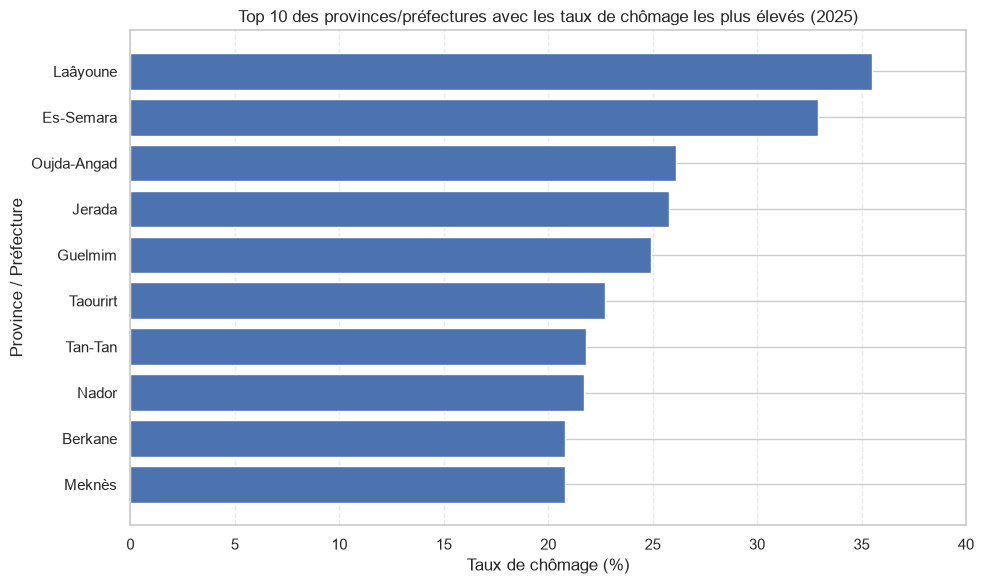

In [30]:
import matplotlib.pyplot as plt

# Select the 10 highest unemployment rates
top_10 = (
    df_2025_national_valid
    .nlargest(10, "Taux_chomage")
    .sort_values("Taux_chomage", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Provinces/Préfectures"],
    top_10["Taux_chomage"]
)

plt.title(
    "Top 10 des provinces/préfectures avec les taux de chômage les plus élevés (2025)"
)
plt.xlabel("Taux de chômage (%)")
plt.ylabel("Province / Préfecture")
plt.xlim(0, 40)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_unemployment_provinces_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

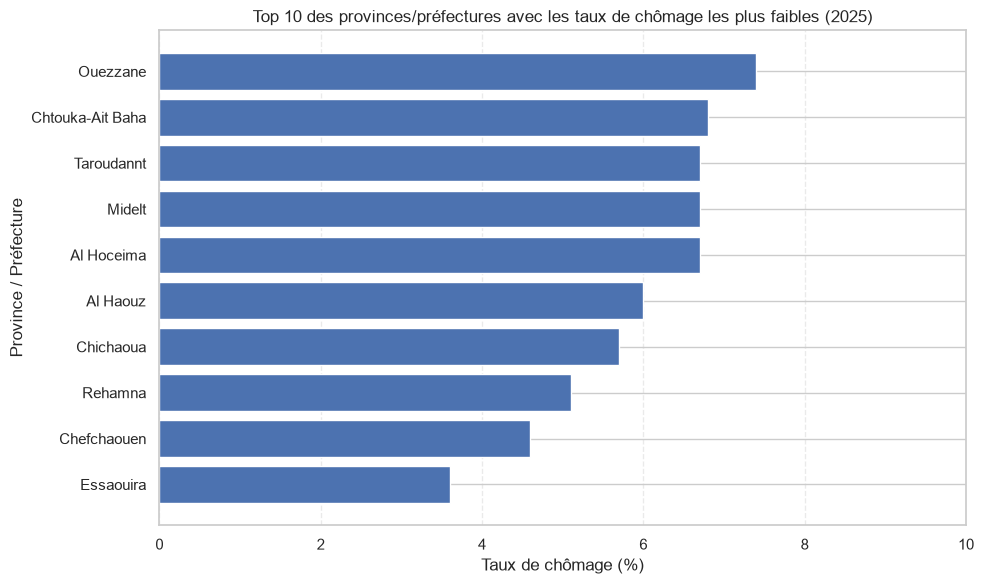

In [31]:
# Select the 10 lowest unemployment rates
bottom_10 = (
    df_2025_national_valid
    .nsmallest(10, "Taux_chomage")
    .sort_values("Taux_chomage", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    bottom_10["Provinces/Préfectures"],
    bottom_10["Taux_chomage"]
)

plt.title(
    "Top 10 des provinces/préfectures avec les taux de chômage les plus faibles (2025)"
)
plt.xlabel("Taux de chômage (%)")
plt.ylabel("Province / Préfecture")
plt.xlim(0, 10)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "bottom_10_unemployment_provinces_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 7.5. Comparaison du chômage entre les milieux urbain et rural

Cette analyse vise à comparer les taux de chômage urbains
et ruraux au niveau des provinces et préfectures.

Nous allons :
- Comparer les taux urbains et ruraux pour chaque territoire.
- Calculer l'écart entre les deux milieux.
- Identifier les territoires présentant les écarts les plus importants.

Pour garantir une comparaison cohérente, nous conservons
uniquement les provinces/préfectures disposant de données
renseignées dans les deux milieux.

In [32]:
# Keep only urban and rural observations for 2025
df_urban_rural = df_province_2025[
    df_province_2025["Milieu"].isin(["Urbain", "Rural"])
].copy()

# Reshape the data: one row per province/prefecture
df_urban_rural_pivot = df_urban_rural.pivot(
    index="Provinces/Préfectures",
    columns="Milieu",
    values="Taux_chomage"
).reset_index()

# Keep only territories with both values available
df_urban_rural_valid = df_urban_rural_pivot.dropna(
    subset=["Urbain", "Rural"]
).copy()

# Calculate the difference between urban and rural rates
df_urban_rural_valid["Ecart_urbain_rural"] = (
    df_urban_rural_valid["Urbain"]
    - df_urban_rural_valid["Rural"]
)

print("Nombre total de provinces/préfectures comparables :",
      len(df_urban_rural_valid))

print("\nAperçu des données :")

display(
    df_urban_rural_valid.head(10).round(2)
)

Nombre total de provinces/préfectures comparables : 26

Aperçu des données :


Milieu,Provinces/Préfectures,Rural,Urbain,Ecart_urbain_rural
1,Al Haouz,4.5,14.4,9.9
4,Benslimane,9.8,16.6,6.8
5,Berkane,18.3,21.8,3.5
6,Berrechid,7.6,16.2,8.6
9,Béni Mellal,8.4,19.6,11.2
11,Chefchaouen,2.3,19.4,17.1
13,Chtouka-Ait Baha,5.8,8.2,2.4
15,El Hajeb,10.6,21.2,10.6
16,El Jadida,4.5,21.2,16.7
17,El Kelâa des Sraghna,9.3,9.8,0.5


In [33]:
# Sort by the largest urban-rural difference
df_urban_rural_sorted = df_urban_rural_valid.sort_values(
    by="Ecart_urbain_rural",
    ascending=False
)

print("Top 10 des écarts urbain-rural les plus élevés :")

display(
    df_urban_rural_sorted[
        [
            "Provinces/Préfectures",
            "Urbain",
            "Rural",
            "Ecart_urbain_rural"
        ]
    ].head(10).round(2).reset_index(drop=True)
)

print("\nTop 10 des écarts urbain-rural les plus faibles :")

display(
    df_urban_rural_sorted[
        [
            "Provinces/Préfectures",
            "Urbain",
            "Rural",
            "Ecart_urbain_rural"
        ]
    ].tail(10).sort_values(
        by="Ecart_urbain_rural",
        ascending=True
    ).round(2).reset_index(drop=True)
)

Top 10 des écarts urbain-rural les plus élevés :


Milieu,Provinces/Préfectures,Urbain,Rural,Ecart_urbain_rural
0,Chefchaouen,19.4,2.3,17.1
1,El Jadida,21.2,4.5,16.7
2,Khémisset,18.7,6.1,12.6
3,Settat,17.7,5.7,12.0
4,Safi,15.7,4.0,11.7
5,Béni Mellal,19.6,8.4,11.2
6,El Hajeb,21.2,10.6,10.6
7,Kénitra,14.4,4.3,10.1
8,Al Haouz,14.4,4.5,9.9
9,Sidi Bennour,14.9,5.5,9.4



Top 10 des écarts urbain-rural les plus faibles :


Milieu,Provinces/Préfectures,Urbain,Rural,Ecart_urbain_rural
0,Nador,21.7,21.5,0.2
1,El Kelâa des Sraghna,9.8,9.3,0.5
2,Fquih Ben Salah,10.9,8.6,2.3
3,Chtouka-Ait Baha,8.2,5.8,2.4
4,Marrakech,10.9,7.8,3.1
5,Berkane,21.8,18.3,3.5
6,Taroudannt,8.9,5.3,3.6
7,Guercif,18.3,12.9,5.4
8,Sefrou,19.2,13.2,6.0
9,Sidi Kacem,11.9,5.5,6.4


In [34]:
print("Statistiques des écarts entre les milieux urbain et rural :")

display(
    df_urban_rural_valid["Ecart_urbain_rural"]
    .describe()
    .round(2)
)

print(
    "\nNombre de provinces où le taux urbain est supérieur au taux rural :",
    (df_urban_rural_valid["Ecart_urbain_rural"] > 0).sum()
)

print(
    "Nombre de provinces où le taux rural est supérieur au taux urbain :",
    (df_urban_rural_valid["Ecart_urbain_rural"] < 0).sum()
)

print(
    "Nombre de provinces où les deux taux sont égaux :",
    (df_urban_rural_valid["Ecart_urbain_rural"] == 0).sum()
)

Statistiques des écarts entre les milieux urbain et rural :


count    26.00
mean      7.70
std       4.45
min       0.20
25%       4.05
50%       7.50
75%      10.48
max      17.10
Name: Ecart_urbain_rural, dtype: float64


Nombre de provinces où le taux urbain est supérieur au taux rural : 26
Nombre de provinces où le taux rural est supérieur au taux urbain : 0
Nombre de provinces où les deux taux sont égaux : 0


### 8.6. Visualisation des écarts entre les milieux urbain et rural

Nous utilisons deux visualisations complémentaires :

- Un nuage de points pour comparer directement les taux de chômage
  urbains et ruraux dans les provinces/préfectures comparables.
- Un graphique en barres pour identifier les dix territoires
  présentant les écarts urbain-rural les plus importants.

Seules les provinces/préfectures disposant de données
dans les deux milieux sont représentées.

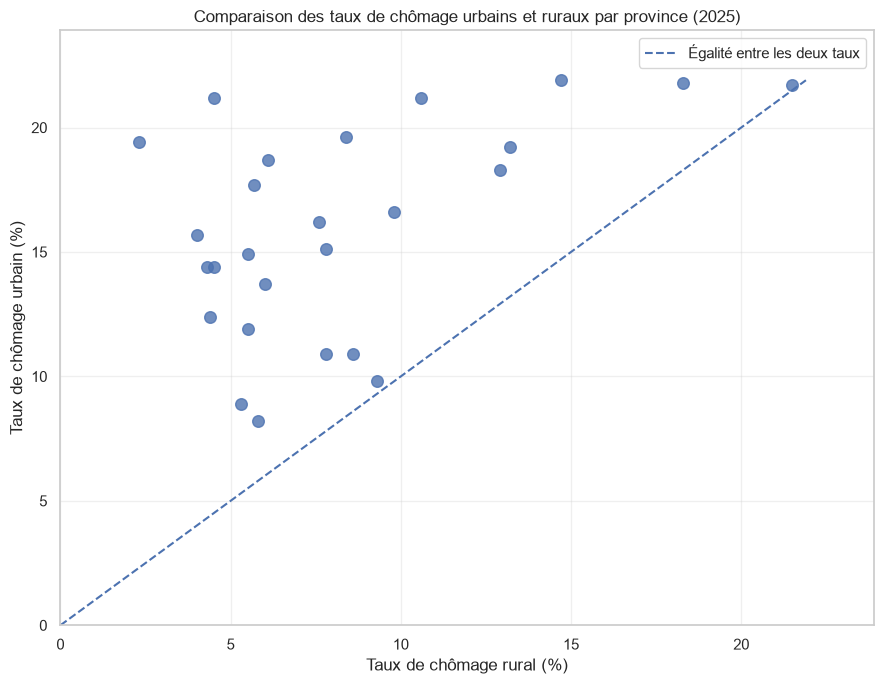

In [35]:
# Scatter plot: Urban vs Rural unemployment rates

plt.figure(figsize=(9, 7))

plt.scatter(
    df_urban_rural_valid["Rural"],
    df_urban_rural_valid["Urbain"],
    s=70,
    alpha=0.8
)

# Reference line: Urban rate = Rural rate
max_value = max(
    df_urban_rural_valid["Rural"].max(),
    df_urban_rural_valid["Urbain"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--",
    label="Égalité entre les deux taux"
)

plt.title(
    "Comparaison des taux de chômage urbains et ruraux par province (2025)"
)
plt.xlabel("Taux de chômage rural (%)")
plt.ylabel("Taux de chômage urbain (%)")

plt.xlim(0, max_value + 2)
plt.ylim(0, max_value + 2)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "urban_vs_rural_scatter_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

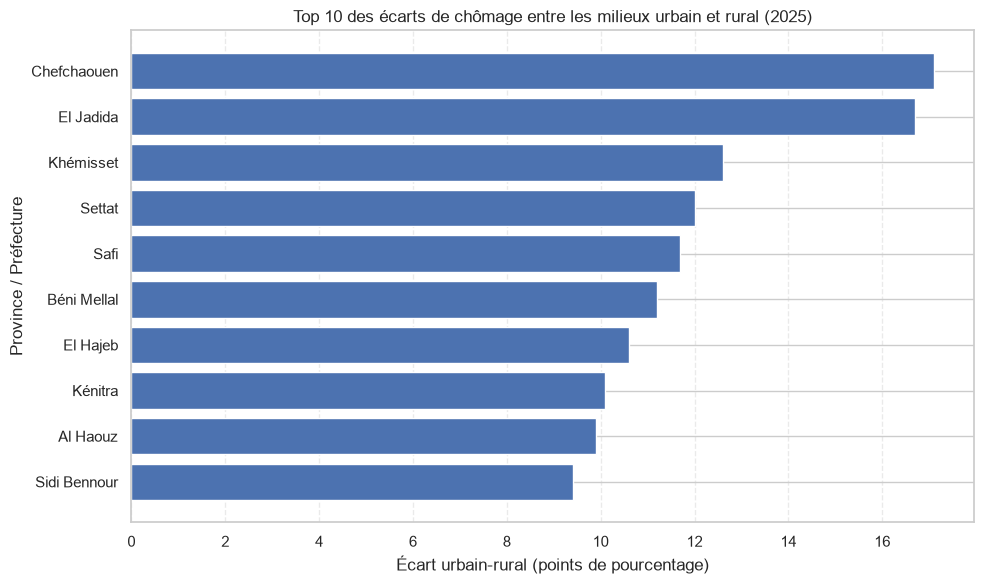

In [36]:
# Select the 10 largest urban-rural differences
top_10_gaps = (
    df_urban_rural_valid
    .nlargest(10, "Ecart_urbain_rural")
    .sort_values("Ecart_urbain_rural", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_gaps["Provinces/Préfectures"],
    top_10_gaps["Ecart_urbain_rural"]
)

plt.title(
    "Top 10 des écarts de chômage entre les milieux urbain et rural (2025)"
)
plt.xlabel("Écart urbain-rural (points de pourcentage)")
plt.ylabel("Province / Préfecture")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_10_urban_rural_gaps_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interprétation des visualisations

Le nuage de points montre que les 26 provinces/préfectures
comparables se situent au-dessus de la ligne d'égalité,
ce qui indique un taux de chômage urbain supérieur au taux rural.

L'écart moyen entre les deux milieux est de 7,70 points
de pourcentage.

Chefchaouen présente l'écart le plus important (17,1 points),
tandis que Nador présente l'écart le plus faible (0,2 point).

Ces résultats concernent uniquement les territoires disposant
de données dans les deux milieux et ne permettent pas
d'établir une relation causale.